# مشروع تقليص الأبعاد على بيانات سرطان الثدي
# PCA


In [1]:
# import libraries
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
%matplotlib inline

In [2]:
## Load the dataset
df = pd.read_csv('C:/Users/ADMIN/Downloads/cancer_data.csv')

In [3]:
df.head(2)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,target_name
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,malignant
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,malignant


In [4]:
df.tail(2)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,target_name
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.3514,0.152,0.2397,0.07016,...,184.60,1821.0,0.16500,0.86810,0.9387,0.265,0.4087,0.12400,0,malignant
568,7.76,24.54,47.92,181.0,0.05263,0.04362,0.0000,0.000,0.1587,0.05884,...,59.16,268.6,0.08996,0.06444,0.0000,0.000,0.2871,0.07039,1,benign


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [6]:
data = df.drop(columns=["target", "target_name"])

In [7]:
data

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pipeline = make_pipeline(StandardScaler(), PCA(n_components=2))
data_pca = pipeline.fit_transform(data)

In [9]:
data_pca

array([[ 9.19283683,  1.94858307],
       [ 2.3878018 , -3.76817174],
       [ 5.73389628, -1.0751738 ],
       ...,
       [ 1.25617928, -1.90229671],
       [10.37479406,  1.67201011],
       [-5.4752433 , -0.67063679]], shape=(569, 2))

In [10]:
pipeline.named_steps['pca'].explained_variance_

array([13.30499079,  5.7013746 ])

In [11]:
pipeline.named_steps['pca'].explained_variance_ratio_

array([0.44272026, 0.18971182])

In [12]:
pipeline.named_steps['pca'].explained_variance_ratio_.sum()  #المكونان الرئيسيان يفسران 63 %من اجمالي التباين

np.float64(0.6324320765155944)

In [33]:
#  Get the PCA model from the pipeline
pca_model = pipeline.named_steps['pca']

# استخراج الأوزان (Loadings) للمركبات الرئيسية
loadings = pca_model.components_

# إنشاء جدول يربط كل متغير أصلي بالمركبتين الأولى والثانية
loadings_df = pd.DataFrame(
    loadings.T, 
    columns=[' PC1', ' PC2'], 
    index=data.columns
)

# عرض مساهمة المتغيرات
print("--- Loadings of the original variables on each principal component ---")
display(loadings_df)

# عرض أهم المتغيرات التي تمثل المركبة الأولى
print("\n--- Most influential variables in the first component PC1 ---")
display(loadings_df[' PC1'].abs().sort_values(ascending=False).head(5))

# عرض أهم المتغيرات التي تمثل المركبة الثانية
print("\n--- Most influential variables in the second component PC2 ---")
display(loadings_df[' PC2'].abs().sort_values(ascending=False).head(5))

--- Loadings of the original variables on each principal component ---


,PC1,PC2
mean radius,0.218902,-0.233857
mean texture,0.103725,-0.059706
mean perimeter,0.227537,-0.215181
mean area,0.220995,-0.231077
mean smoothness,0.142590,0.186113
mean compactness,0.239285,0.151892
mean concavity,0.258400,0.060165
mean concave points,0.260854,-0.034768
mean symmetry,0.138167,0.190349
mean fractal dimension,0.064363,0.366575



--- Most influential variables in the first component PC1 ---


mean concave points     0.260854
mean concavity          0.258400
worst concave points    0.250886
mean compactness        0.239285
worst perimeter         0.236640
Name:  PC1, dtype: float64


--- Most influential variables in the second component PC2 ---


mean fractal dimension     0.366575
fractal dimension error    0.280092
worst fractal dimension    0.275339
mean radius                0.233857
compactness error          0.232716
Name:  PC2, dtype: float64

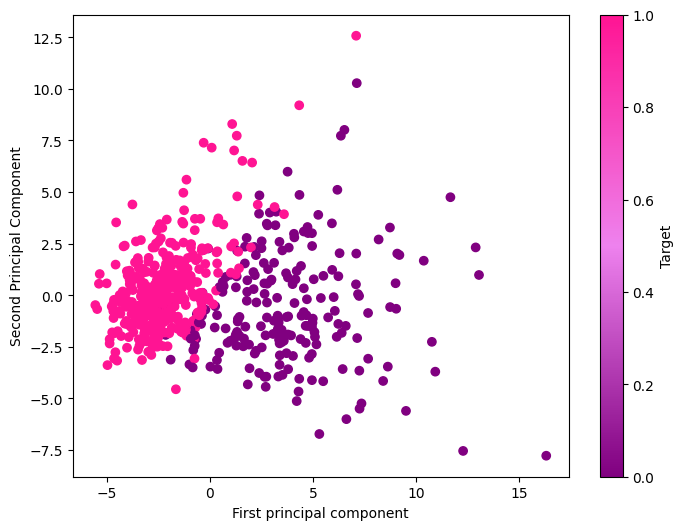

In [14]:
from matplotlib.colors import LinearSegmentedColormap

# إنشاء تدرج مخصص من البنفسجي إلى الوردي
pink_purple_cmap = LinearSegmentedColormap.from_list(
    "pink_purple", ["purple", "violet", "deeppink"]
)        
plt.figure(figsize=(8,6))
plt.scatter(data_pca[:,0],data_pca[:,1],c=df['target'],cmap=pink_purple_cmap)
plt.xlabel('First principal component')
plt.ylabel('Second Principal Component')
plt.colorbar(label="Target")
plt.show()

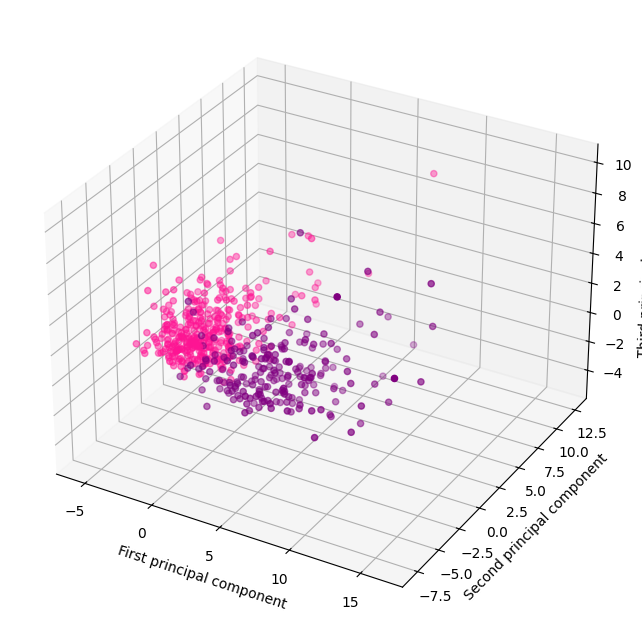

In [15]:
# 1. Recalculer l'ACP avec 3 composantes pour le graphique 3D
scaled_data = pipeline.named_steps['standardscaler'].transform(data)
pca_3d = PCA(n_components=3)
data_pca_3d = pca_3d.fit_transform(scaled_data)

# 2. Tracer le graphique 3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')

scatter = ax.scatter(
    data_pca_3d[:, 0],
    data_pca_3d[:, 1],
    data_pca_3d[:, 2],
    c=df["target"],
    cmap=pink_purple_cmap
)

# 3. Nommer les trois axes
ax.set_xlabel('First principal component')
ax.set_ylabel('Second principal component')
ax.set_zlabel('Third principal component')

# 4. Ajouter la barre de couleur pour la cible
pink_purple_cmap = LinearSegmentedColormap.from_list(
    "pink_purple", ["purple", "mediumvioletred", "deeppink"]
)
plt.show()

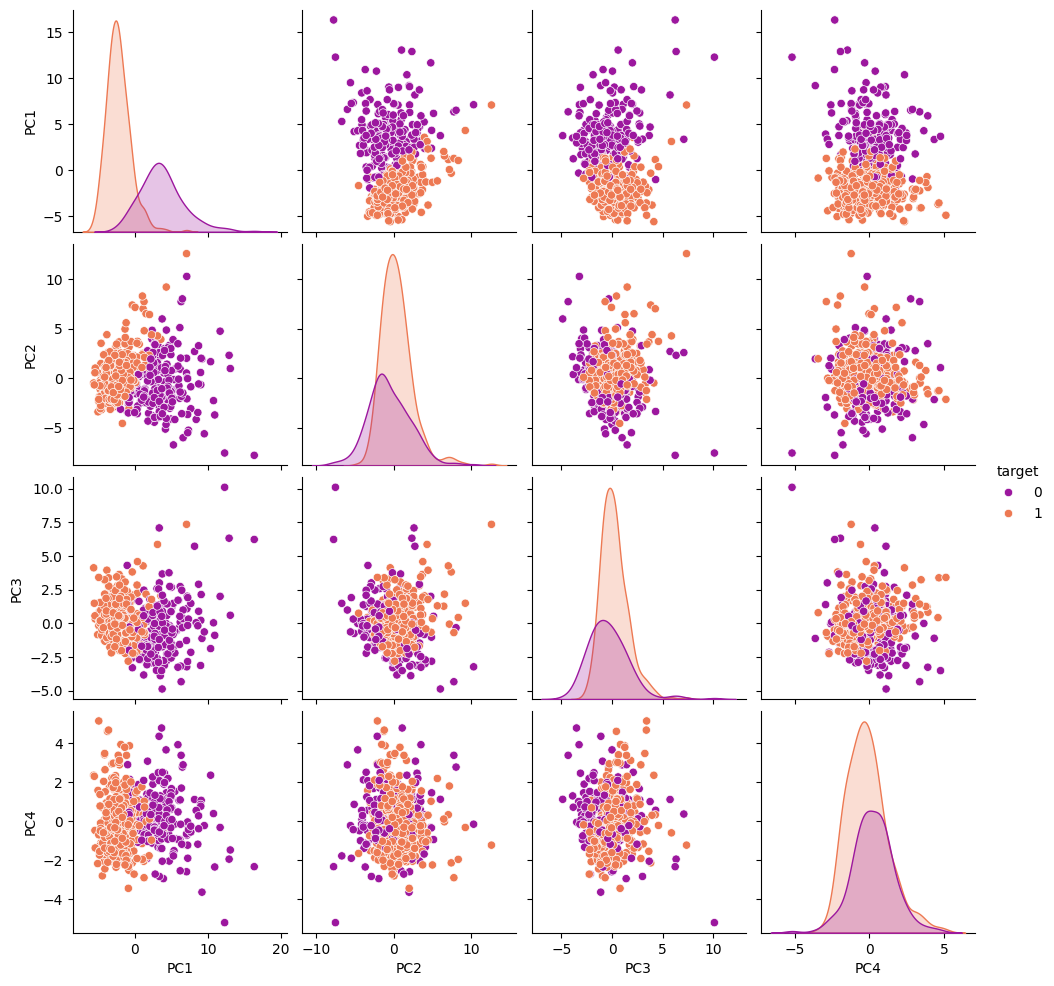

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Recalculer l'ACP avec 4 composantes
pca_4 = PCA(n_components=4)
data_pca_4 = pca_4.fit_transform(scaled_data)

# 2. Créer le DataFrame avec les 4 composantes et la cible
pca_df = pd.DataFrame(
    data_pca_4,
    columns=['PC1', 'PC2', 'PC3', 'PC4']
)
pca_df['target'] = df['target'].values

# 3. Tracer le grid de comparaison (pairplot)
sns.pairplot(
    pca_df,
    hue='target',
    palette='plasma',
    diag_kind='kde'
)

plt.show()

In [22]:
pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data_pca)
y=df["target"]

In [24]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
X=X_pca

In [35]:
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential
# 1. تقسيم البيانات المستخرجة من PCA 2D
X_train_pca2, X_test_pca2, y_train_pca2, y_test_pca2 = train_test_split(X, y, test_size=0.2, random_state=42)
# 2. بناء هيكل الشبكة العصبية بمدخلين فقط
model_pca2 = Sequential([
    Dense(16, activation='relu', input_shape=(2,)),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

# 3. تجميع النموذج
model_pca2.compile(optimizer='adam',
                   loss='binary_crossentropy',
                   metrics=['accuracy'])

# 4. تدريب النموذج
history_pca2 = model_pca2.fit(X_train_pca2, y_train_pca2,
epochs=50,
batch_size=16,
validation_split=0.1,
verbose=1)
# 5.
loss_pca2, accuracy_pca2 = model_pca2.evaluate(X_test_pca2, y_test_pca2)
print(f"\nAccuracy PCA 2D : {accuracy_pca2 * 100:.2f}%")

Epoch 1/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step - accuracy: 0.3081 - loss: 0.7936 - val_accuracy: 0.4565 - val_loss: 0.6811
Epoch 2/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4621 - loss: 0.6854 - val_accuracy: 0.5652 - val_loss: 0.5996
Epoch 3/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7555 - loss: 0.6047 - val_accuracy: 0.8696 - val_loss: 0.5329
Epoch 4/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8900 - loss: 0.5372 - val_accuracy: 0.9130 - val_loss: 0.4736
Epoch 5/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9071 - loss: 0.4759 - val_accuracy: 0.9348 - val_loss: 0.4181
Epoch 6/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9242 - loss: 0.4185 - val_accuracy: 0.9348 - val_loss: 0.3676
Epoch 7/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9242 - loss: 0.3685 - val_accuracy: 0.9348 - val_loss: 0.3239
Epoch 8/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9315 - loss: 0.3256 - val_accuracy: 0.9565 - val_

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


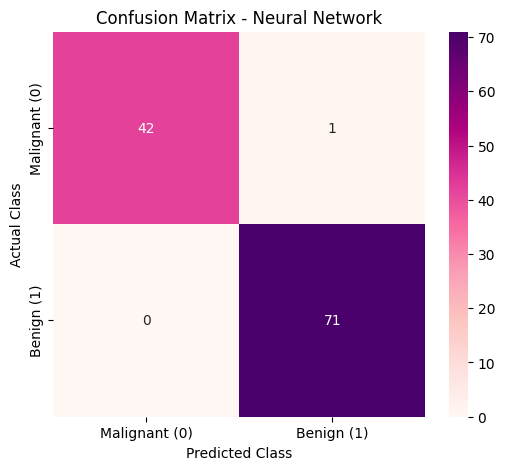

Classification Report:
              precision    recall  f1-score   support

   Malignant       1.00      0.98      0.99        43
      Benign       0.99      1.00      0.99        71

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



In [28]:
from sklearn.metrics import confusion_matrix, classification_report

# 1. Predict class probabilities
y_pred_prob = model_pca2.predict(X_test_pca2)

# 2. Convert probabilities to binary class outputs (threshold of 0.5)
y_pred = (y_pred_prob > 0.5).astype(int)

# 3. Compute confusion matrix
cm = confusion_matrix(y_test_pca2, y_pred)

# 4. Plot the confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='RdPu',
            xticklabels=['Malignant (0)', 'Benign (1)'],
            yticklabels=['Malignant (0)', 'Benign (1)'])
plt.title('Confusion Matrix - Neural Network')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

# 5. Display classification report
print("Classification Report:")
print(classification_report(y_test_pca2, y_pred, target_names=['Malignant', 'Benign']))